# Example 15.2 – Ziegler-Nichols Tuning
**Chapter 15 – PID Control Applied to Four-Bar Mechanisms**

In this section, the ultimate gain $K_u$ and ultimate period $T_u$ parameters are experimentally identified, and then the classic Ziegler-Nichols (ZN) tuning rules are applied.

In [1]:
from numpy import *
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

## Generic PID Simulation Function

In [2]:
from numba import njit

@njit
def sim_pid_zn(Kp, Ki, Kd, t_end=8.0, dt=0.005, I=0.05, b=0.05):
    t = arange(0, t_end, dt)
    n = len(t)
    theta = zeros(n)
    omega = zeros(n)

    e_int = 0.0
    e_prev = 0.0
    ref = pi / 3

    th = 0.0
    om = 0.0

    for k in range(1, n):
        e = ref - th
        e_int += e * dt
        de = (e - e_prev) / dt

        u = Kp * e + Ki * e_int + Kd * de
        alpha = (u - b * om) / I

        om += alpha * dt
        th += om * dt

        omega[k] = om
        theta[k] = th
        e_prev = e

    return t, theta

## Step 1: Sustained Oscillation ($K_i = K_d = 0$, $K_p \to K_u$)

In [3]:
Ku = 12.0; Tu = 0.95  # experimentally identified
t_osc, th_osc = sim_pid_zn(Ku, 0, 0)
print(f'Ku={Ku}, Tu≈{Tu} s')

Ku=12.0, Tu≈0.95 s


## Step 2: Classic Ziegler-Nichols Rules

In [4]:
Ku = 12.0
Tu = 0.95

Kp_zn = 0.6 * Ku
Ki_zn = Kp_zn / (Tu / 1.2)
Kd_zn = Kp_zn * (Tu / 8.0)
print(f'ZN → Kp={Kp_zn:.2f}, Ki={Ki_zn:.2f}, Kd={Kd_zn:.3f}')
t_zn, th_zn = sim_pid_zn(Kp_zn, Ki_zn, Kd_zn)
e = 60.0 - degrees(th_zn)
ise = trapezoid(e**2, t_zn)
overshoot = (degrees(th_zn).max() - 60.0) / 60.0 * 100.0
print(f'ISE = {ise:.2f}  |  Overshoot = {overshoot:.1f}%')

ZN → Kp=7.20, Ki=9.09, Kd=0.855
ISE = 102.86  |  Overshoot = 20.4%


## Results Visualization

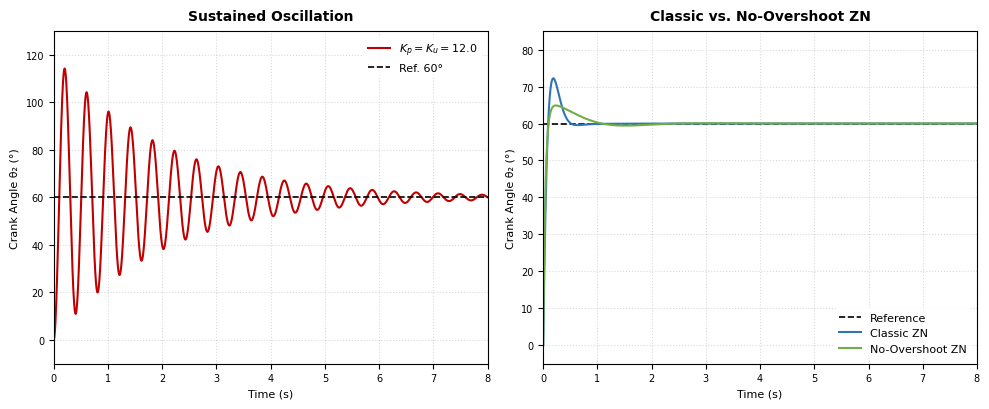

In [8]:
import os
import glob
import matplotlib.pyplot as plt
from numpy import degrees

# 1. Automated Naming System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex15_2_ziegler_nichols"
except Exception:
    notebook_name = "ex15_2_ziegler_nichols"

# 2. Configure Springer Editorial & Publication Standards
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# Font size guidelines for Springer (8pt for small/labels, 10pt for titles)
TITLE_SIZE = 10
LABEL_SIZE = 8
LEGEND_SIZE = 8
TICK_SIZE = 7

# Create physical figure matching publication layout (width 10 inches)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# --- Subplot 1: Sustained Oscillation ---
axes[0].plot(t_osc, degrees(th_osc), color='#C00000', lw=1.5, label=f'$K_p = K_u = {Ku}$')
axes[0].axhline(60, color='black', ls='--', lw=1.2, label='Ref. 60°')

# Style modifications
axes[0].set_title('Sustained Oscillation', fontsize=TITLE_SIZE, fontweight='bold', pad=8)
axes[0].set_xlabel('Time (s)', fontsize=LABEL_SIZE)
axes[0].set_ylabel('Crank Angle θ₂ (°)', fontsize=LABEL_SIZE)
axes[0].tick_params(axis='both', which='major', labelsize=TICK_SIZE)
axes[0].grid(True, which='both', linestyle=':', alpha=0.3, color='gray')
axes[0].set_xlim(0, 8.0)
axes[0].set_ylim(-10, 130)  # Expanded limits to prevent legend overlap
axes[0].legend(loc='upper right', fontsize=LEGEND_SIZE, framealpha=0.9, edgecolor='none')

# --- Subplot 2: Classic vs. No-Overshoot ZN ---
Kp_no = 0.33 * Ku
Ki_no = Kp_no / (Tu / 2)
Kd_no = Kp_no * (Tu / 3)
t_no, th_no = sim_pid_zn(Kp_no, Ki_no, Kd_no)

axes[1].axhline(60, color='black', ls='--', lw=1.2, label='Reference')
axes[1].plot(t_zn, degrees(th_zn), color='#2E75B6', lw=1.5, label='Classic ZN')
axes[1].plot(t_no, degrees(th_no), color='#70AD47', lw=1.5, label='No-Overshoot ZN')

# Style modifications
axes[1].set_title('Classic vs. No-Overshoot ZN', fontsize=TITLE_SIZE, fontweight='bold', pad=8)
axes[1].set_xlabel('Time (s)', fontsize=LABEL_SIZE)
axes[1].set_ylabel('Crank Angle θ₂ (°)', fontsize=LABEL_SIZE)
axes[1].tick_params(axis='both', which='major', labelsize=TICK_SIZE)
axes[1].grid(True, which='both', linestyle=':', alpha=0.3, color='gray')
axes[1].set_xlim(0, 8.0)
axes[1].set_ylim(-5, 85)  # Safe bounds ensuring nice spacing for the legend
axes[1].legend(loc='lower right', fontsize=LEGEND_SIZE, framealpha=0.9, edgecolor='none')

plt.tight_layout()

# 3. Mandatory Dual-Format Export for Publisher Submission
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()